# Segment and sale


## 1. Load the data


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

DATA = 'https://raw.githubusercontent.com/cyrillee0413-bit/dao2702-properties/refs/heads/main/properties2025.csv'
TABLES = Path('tables')
FIGURES = Path('figures')
TABLES.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

raw = pd.read_csv(DATA)
print('Raw rows and columns:', raw.shape)
print(raw[['segment', 'sale', 'price', 'area', 'level', 'date']].head().to_string(index=False))


Raw rows and columns: (24151, 12)
segment     sale   price    area    level   date
    CCR   Resale 9050000 6060.13 16 to 20 Dec-25
    RCR   Resale 1698000 1033.34 11 to 15 Dec-25
    RCR New Sale 2583000  818.06 31 to 35 Dec-25
    RCR New Sale 2991000  861.12 56 to 60 Dec-25
    RCR New Sale 3102000 1216.33 11 to 15 Dec-25


## 2. Define the sample and PSF


In [2]:
EXCLUDE_BASEMENT = True
if EXCLUDE_BASEMENT:
    df = raw.loc[~raw['level'].str.startswith('B', na=False)].copy()
else:
    df = raw.copy()

df['psf'] = df['price'] / df['area']
df['month'] = pd.to_datetime(df['date'], format='%b-%y')

SEGMENT_ORDER = ['CCR', 'RCR', 'OCR']
SALE_ORDER = ['New Sale', 'Sub Sale', 'Resale']
SEGMENT_COLORS = ['#2a78d6', '#eb6834', '#1baf7a']
SALE_COLORS = ['#4a3aa7', '#e87ba4', '#008300']

print('Analysed records:', len(df))
print('Excluded records:', len(raw) - len(df))
print('Missing values in relevant columns:')
print(df[['segment', 'sale', 'price', 'area', 'psf', 'month']].isna().sum().to_string())
print('Identical rows retained:', df.duplicated().sum())
print('Non-positive prices:', (df['price'] <= 0).sum())
print('Non-positive areas:', (df['area'] <= 0).sum())


Analysed records: 24149
Excluded records: 2
Missing values in relevant columns:
segment    0
sale       0
price      0
area       0
psf        0
month      0
Identical rows retained: 1442
Non-positive prices: 0
Non-positive areas: 0


## 3. Segment summary


In [3]:
segment_summary = df.groupby('segment')['psf'].agg(['count', 'median'])
segment_summary = segment_summary.reindex(SEGMENT_ORDER)
segment_summary = segment_summary.rename(columns={'count': 'records', 'median': 'median_psf'})
segment_summary['share_pct'] = segment_summary['records'] / len(df) * 100
segment_summary.to_csv(TABLES / 'segment_summary.csv')
print(segment_summary.round({'median_psf': 2, 'share_pct': 2}).to_string())


         records  median_psf  share_pct
segment                                
CCR         4320     2676.07      17.89
RCR         8795     2417.46      36.42
OCR        11034     1846.14      45.69


## 4. Sale summary


In [4]:
sale_summary = df.groupby('sale')['psf'].agg(['count', 'median'])
sale_summary = sale_summary.reindex(SALE_ORDER)
sale_summary = sale_summary.rename(columns={'count': 'records', 'median': 'median_psf'})
sale_summary['share_pct'] = sale_summary['records'] / len(df) * 100
sale_summary.to_csv(TABLES / 'sale_summary.csv')
print(sale_summary.round({'median_psf': 2, 'share_pct': 2}).to_string())

ccr_ocr_gap = (segment_summary.loc['CCR', 'median_psf'] / segment_summary.loc['OCR', 'median_psf'] - 1) * 100
new_resale_gap = (sale_summary.loc['New Sale', 'median_psf'] / sale_summary.loc['Resale', 'median_psf'] - 1) * 100
print(f'CCR versus OCR median PSF gap: {ccr_ocr_gap:.1f}%')
print(f'New Sale versus Resale median PSF gap: {new_resale_gap:.1f}%')


          records  median_psf  share_pct
sale                                    
New Sale    10647     2571.78      44.09
Sub Sale      939     2096.03       3.89
Resale      12563     1747.11      52.02
CCR versus OCR median PSF gap: 45.0%
New Sale versus Resale median PSF gap: 47.2%


## 5. Joint comparison: segment and sale


In [5]:
segment_sale_summary = df.groupby(['segment', 'sale'])['psf'].agg(['count', 'median'])
segment_sale_summary = segment_sale_summary.rename(columns={'count': 'records', 'median': 'median_psf'})
segment_sale_summary.to_csv(TABLES / 'segment_sale_summary.csv')

median_matrix = segment_sale_summary['median_psf'].unstack('sale').reindex(index=SEGMENT_ORDER, columns=SALE_ORDER)
count_matrix = segment_sale_summary['records'].unstack('sale').reindex(index=SEGMENT_ORDER, columns=SALE_ORDER)
within_segment_gap = (median_matrix['New Sale'] / median_matrix['Resale'] - 1) * 100

print('Median PSF (S$/sqft):')
print(median_matrix.round(2).to_string())
print('Records per group:')
print(count_matrix.to_string())
print('New Sale versus Resale median PSF gap (%):')
print(within_segment_gap.round(1).to_string())


Median PSF (S$/sqft):
sale     New Sale  Sub Sale   Resale
segment                             
CCR       3070.87   2954.73  2179.14
RCR       2789.02   2196.55  1916.10
OCR       2254.25   1939.81  1532.88
Records per group:
sale     New Sale  Sub Sale  Resale
segment                            
CCR          1910        94    2316
RCR          4400       415    3980
OCR          4337       430    6267
New Sale versus Resale median PSF gap (%):
segment
CCR    40.9
RCR    45.6
OCR    47.1


## 6. Segment and sale chart


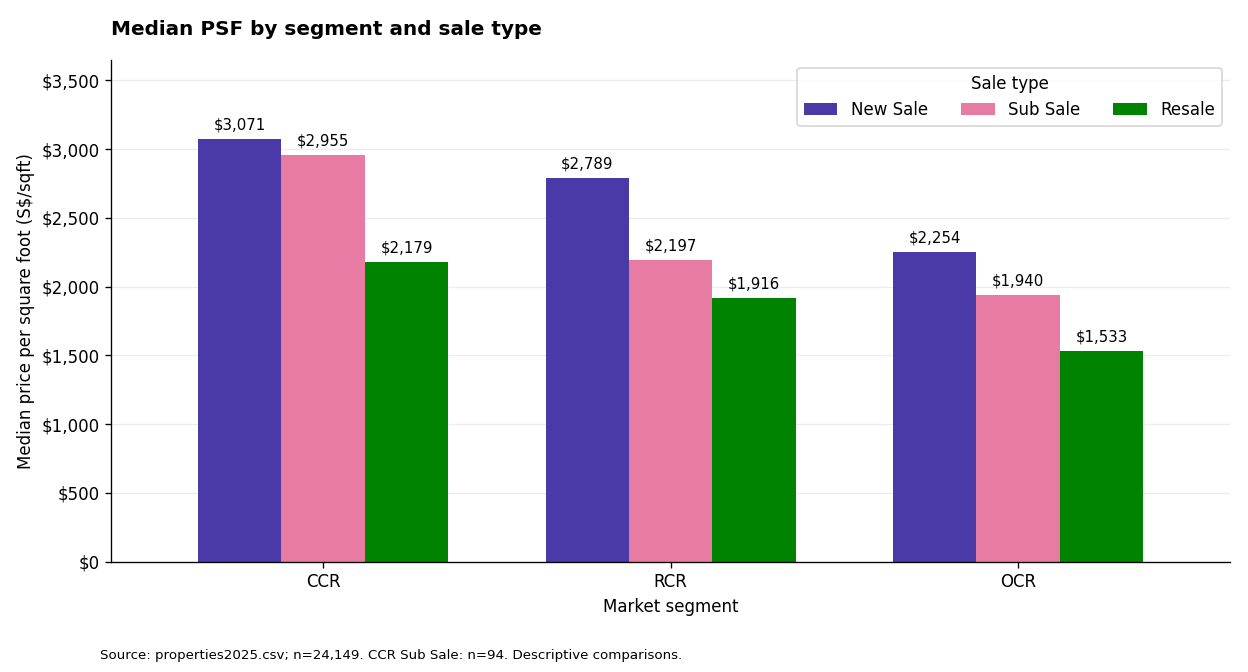

In [6]:
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
ax = median_matrix.plot(kind='bar', color=SALE_COLORS, figsize=(10.4, 5.6), width=0.72, rot=0)
for container in ax.containers:
    ax.bar_label(container, labels=[f'${value:,.0f}' for value in container.datavalues], padding=4, fontsize=9)
ax.set_title('Median PSF by segment and sale type', loc='left', fontweight='bold', pad=15)
ax.set_xlabel('Market segment')
ax.set_ylabel('Median price per square foot (S$/sqft)')
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax.set_ylim(0, 3650)
ax.grid(axis='y', alpha=0.22)
ax.set_axisbelow(True)
ax.legend(title='Sale type', loc='upper right', ncol=3)
fig = ax.get_figure()
fig.text(0.08, 0.02, f'Source: properties2025.csv; n={len(df):,}. CCR Sub Sale: n={count_matrix.loc["CCR", "Sub Sale"]:,}. Descriptive comparisons.', fontsize=8)
fig.tight_layout(rect=[0, 0.06, 1, 1])
fig.savefig(FIGURES / 'fig02_segment_by_sale.png', dpi=240)
plt.show()
